# Multinominal logistic regression life span to predict danger index

In this part of the notebook we will do multinominal logistic regression to predict danger index from max life span.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn import linear_model
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multiclass import OneVsOneClassifier
from sklearn.metrics import ConfusionMatrixDisplay

df = pd.read_csv("dataset_2191_sleep.csv")
df= df.dropna()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_weight           62 non-null     float64
 1   brain_weight          62 non-null     float64
 2   max_life_span         62 non-null     str    
 3   gestation_time        62 non-null     str    
 4   predation_index       62 non-null     int64  
 5   sleep_exposure_index  62 non-null     int64  
 6   danger_index          62 non-null     int64  
 7   total_sleep           62 non-null     str    
dtypes: float64(2), int64(3), str(3)
memory usage: 4.0 KB


In [2]:
df.head()

,body_weight,brain_weight,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,total_sleep
0,6654.000,5712.0,38.6,645,3,5,3,3.3
1,1.000,6.6,4.5,42,3,1,3,8.3
2,3.385,44.5,14,60,1,1,1,12.5
3,0.920,5.7,?,25,5,2,3,16.5
4,2547.000,4603.0,69,624,3,5,4,3.9


To filter out the cells that contain unknown data, denoted as '?', we will convert ? to nan and then drop these values.

In [3]:
df = df.replace("?", np.nan)
df = df.dropna()
df.info()

<class 'pandas.DataFrame'>
Index: 51 entries, 0 to 60
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_weight           51 non-null     float64
 1   brain_weight          51 non-null     float64
 2   max_life_span         51 non-null     str    
 3   gestation_time        51 non-null     str    
 4   predation_index       51 non-null     int64  
 5   sleep_exposure_index  51 non-null     int64  
 6   danger_index          51 non-null     int64  
 7   total_sleep           51 non-null     str    
dtypes: float64(2), int64(3), str(3)
memory usage: 3.6 KB


Here we see that max life span and total sleep is a str, in order to fit the model we need a float so we will convert the str to a float in the next cell.

In [4]:
df["max_life_span"] = df["max_life_span"].astype(float)
df["danger_index"] = df["danger_index"].astype(float)
df["total_sleep"] = df["total_sleep"].astype(float)

To be able to asses the right shuffle type for our data, we will see how the data is distributed over the different danger indexes in the next cell.

In [5]:
danger = df['danger_index'] 
danger_counts = danger.value_counts() 
print(danger_counts)

danger_index
1.0    15
2.0    12
4.0     9
3.0     8
5.0     7
Name: count, dtype: int64


Here we see that the data isn't evenly distributed and thus imbalanced, which is why we chose to use stratified shuffle split. In the next cell we have an initial look at a OnevsRest model with a train size of 0.7 to have an first idea of the model and the train/test distribution.

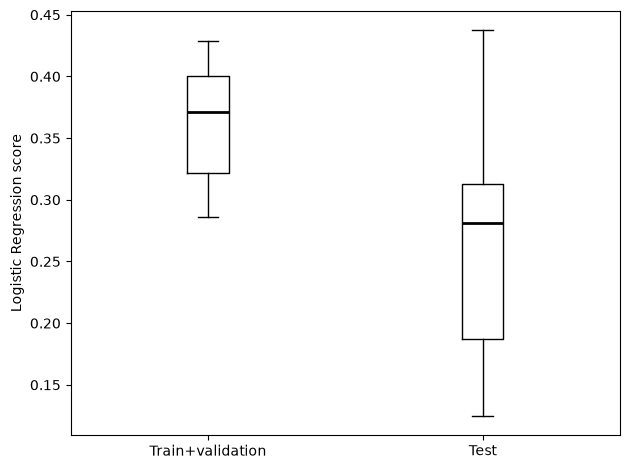

0.37142857142857144
0.28125


In [6]:
mlifespan = df['max_life_span']

y = df['danger_index'].to_numpy()
x = np.array(mlifespan).reshape(-1,1)

n_trials = 10
score_tv = list()
score_te = list()
split = StratifiedShuffleSplit(n_splits=n_trials, train_size=0.7,random_state=42)
for train, test in split.split(x, y):
    x_tv,y_tv = x[train], y[train]
    x_te,y_te = x[test], y[test]

    ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000,C=np.inf)).fit(x_tv, y_tv)
    score_tv.append(ovr.score(x_tv,y_tv))
    score_te.append(ovr.score(x_te,y_te))

plt.boxplot([score_tv,score_te],medianprops=dict(color='k', linewidth=2))
plt.ylabel('Logistic Regression score')
plt.xticks([1,2],labels=['Train+validation','Test'])
plt.tight_layout()
plt.show()

print(np.median(score_tv))
print(np.median(score_te))

The score of this model isn't very good. We will look whether the use of different parameters and hyperparameters will improve our model. The next cell looks at the best k-fold for this data, we only test 2-5 because the dataset has 50 points and otherwise the samples will become to small.

In [7]:
from sklearn.model_selection import cross_val_score

mlifespan = df['max_life_span']

y = df['danger_index'].to_numpy()
x = np.array(mlifespan).reshape(-1,1)

ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000))

n_repeats = 50

# Number of folds in k-fold
ks = [ 2, 3, 4, 5,]
print("\nk-fold")
for k in ks:
    cv = RepeatedStratifiedKFold(n_splits=k, n_repeats=n_repeats // 5, random_state=42)
    scores = cross_val_score(ovr, x, y, cv=cv, n_jobs=4)
    print(f"k={k:2d}  mean={scores.mean():.4f}  std={scores.std():.4f}")


k-fold
k= 2  mean=0.3078  std=0.0688
k= 3  mean=0.2922  std=0.0752
k= 4  mean=0.3053  std=0.0809
k= 5  mean=0.2969  std=0.1013


Here we can see that k-fold= 2 best mean for logistic regression score and least std.for the test sample of the data. However the median score of the model is still very low. So now I will compare the OnevsRest model to the OnevsOne model, to see if a different model might work better.

In [8]:
mlifespan = df['max_life_span']

y = df['danger_index'].to_numpy()
x = np.array(mlifespan).reshape(-1,1)

ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000))
ovo = OneVsOneClassifier(LogisticRegression(max_iter=1000))
models = [ovr,ovo]

param_grid = {'estimator__C': np.logspace(-4,3,num=8)}

n_outer_splits = 2
n_repeats = 5
n_inner_splits = 2

test_scores = np.zeros((n_outer_splits*n_repeats,len(models)))
model_choice = np.zeros(n_outer_splits*n_repeats)
param_choice = np.zeros(n_outer_splits*n_repeats)

outercv = RepeatedStratifiedKFold(n_splits=n_outer_splits,n_repeats=n_repeats,random_state=42)
innercv = StratifiedKFold(n_splits=n_inner_splits,shuffle=True,random_state=42)

for k, (train, test) in enumerate(outercv.split(x,y)):
    x_tv,y_tv = x[train], y[train]
    x_te,y_te = x[test], y[test]

    estimators = list()
    scores = list()
    param = list()
    for model in models:
        param_cv = GridSearchCV(model,param_grid,n_jobs=4,cv=innercv)
        param_cv.fit(x_tv,y_tv)
        scores.append(param_cv.best_score_)
        estimators.append(param_cv.best_estimator_)
        param.append(param_cv.best_params_['estimator__C'])

    choose = int(np.argmax(scores))
    model_choice[k] = choose
    param_choice[k] = param[choose]
    for j, model in enumerate(estimators):
        model.fit(x_tv,y_tv)
        test_scores[k,j] = model.score(x_te,y_te)

print(np.mean(model_choice))
print(np.mean(test_scores[:,0]-test_scores[:,1]))

0.2
0.015384615384615385


In [9]:
print(param_choice)

[1.e-01 1.e-01 1.e-01 1.e+00 1.e-01 1.e-04 1.e-01 1.e-03 1.e-02 1.e-03]


The OnevsRestclassifier is better because this score is closer to zero. The print param_choice shows the best choice for c in each case, the most stable choice is 1.e-01, because that there 5 times, the other 5 are 4 different ones. And before we found that k-fold=2 was the best. Next we will fit the final model and make a confusion matrix.

In [23]:
mlifespan = df['max_life_span']

y = df['danger_index'].to_numpy()
x = np.array(mlifespan).reshape(-1,1)

model1 = OneVsRestClassifier(LogisticRegression(max_iter=1000, C=1.e-01))
skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
scores = cross_val_score(ovr, x, y, cv=skf)

model1.fit(x,y)
print(model1.score(x,y))
print(model1.estimators_[0].coef_)

0.37254901960784315
[[0.01976447]]


[[10  5  0  0  0]
 [ 3  9  0  0  0]
 [ 1  7  0  0  0]
 [ 6  3  0  0  0]
 [ 7  0  0  0  0]]


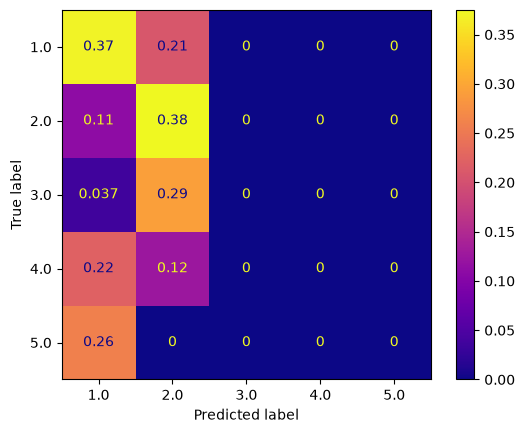

In [24]:
from sklearn.metrics import confusion_matrix
yhat = model1.predict(x)
confmat = confusion_matrix(y,yhat)
print(confmat)
ConfusionMatrixDisplay.from_estimator(model1,x,y,normalize='pred',cmap='plasma')
plt.savefig("CM_danger_lifespan.png", dpi=300)
plt.show()

As we can see in the confusion matrix danger index cannot be predicted by max life span.

### Extra visualitation

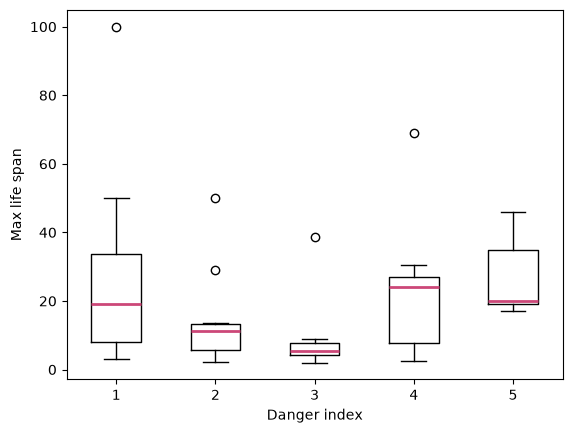

In [12]:
danger1 = df[df['danger_index']==1.0]['max_life_span']
danger2 = df[df['danger_index']==2.0]['max_life_span']
danger3 = df[df['danger_index']==3.0]['max_life_span']
danger4 = df[df['danger_index']==4.0]['max_life_span']
danger5 = df[df['danger_index']==5.0]['max_life_span']

plt.boxplot([danger1,danger2,danger3,danger4,danger5],medianprops=dict(color='#cc4778', linewidth=2))
plt.ylabel('Max life span')
plt.xlabel('Danger index')
plt.savefig("box_danger_lifespan.png", dpi=300)
plt.show()

In this graph we can see that the max life span overlaps for all the different danger indexes, which already predict that our model wouldn't perform well.

## Total sleep

In this part we will seen if total sleep can be used to predict danger index. We used stratified shuffle for the same reason as before. In the next cell we have an initail model with a train size of 0.7, we will adjust thing to make it better during the rest of the cells in this part.

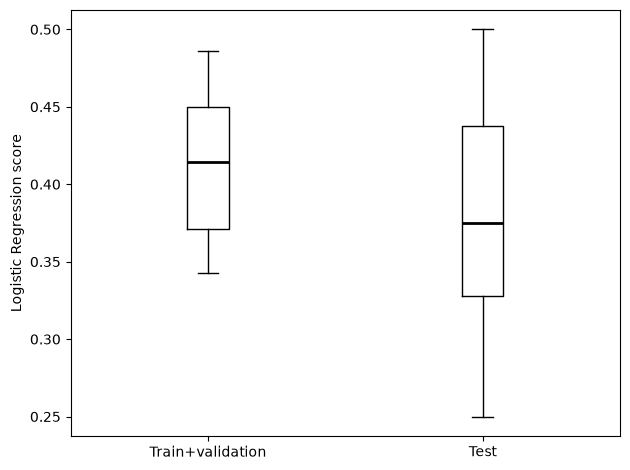

0.41428571428571426
0.375


In [13]:
totalsleep = df['total_sleep']

y = df['danger_index'].to_numpy()
x = np.array(totalsleep).reshape(-1,1)

n_trials = 10
score_tv = list()
score_te = list()
split = StratifiedShuffleSplit(n_splits=n_trials, train_size=0.7,random_state=42)
for train, test in split.split(x, y):
    x_tv,y_tv = x[train], y[train]
    x_te,y_te = x[test], y[test]

    ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000,C=np.inf)).fit(x_tv, y_tv)
    score_tv.append(ovr.score(x_tv,y_tv))
    score_te.append(ovr.score(x_te,y_te))

plt.boxplot([score_tv,score_te],medianprops=dict(color='k', linewidth=2))
plt.ylabel('Logistic Regression score')
plt.xticks([1,2],labels=['Train+validation','Test'])
plt.tight_layout()
plt.show()

print(np.median(score_tv))
print(np.median(score_te))

From this initial model we can already see that the score is slightly beter as the model were we used max lifespan. In the next cell we will see what number of k- folds works best.

In [14]:
from sklearn.model_selection import cross_val_score

totalsleep = df['total_sleep']

y = df['danger_index'].to_numpy()
x = np.array(totalsleep).reshape(-1,1)

ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000))

n_repeats = 50

# Number of folds in k-fold
ks = [ 2, 3, 4, 5,]
print("\nk-fold")
for k in ks:
    cv = RepeatedStratifiedKFold(n_splits=k, n_repeats=n_repeats // 5, random_state=42)
    scores = cross_val_score(ovr, x, y, cv=cv, n_jobs=4)
    print(f"k={k:2d}  mean={scores.mean():.4f}  std={scores.std():.4f}")


k-fold
k= 2  mean=0.3838  std=0.0535
k= 3  mean=0.3608  std=0.0640
k= 4  mean=0.3846  std=0.0909
k= 5  mean=0.3740  std=0.0941


We see that k-fold=2 and k-fold=4 give a similar mean, but a slightly different std. Since the dataset only contains 51 data points, we will chose k-fold=2 because at 4 the samples will become quite small and the difference between the two is almost noting. We will now see if a OnevsOne model might work better and determine what the best c is for our model.

In [15]:
totalsleep = df['total_sleep']

y = df['danger_index'].to_numpy()
x = np.array(totalsleep).reshape(-1,1)

ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000))
ovo = OneVsOneClassifier(LogisticRegression(max_iter=1000))
models = [ovr,ovo]

param_grid = {'estimator__C': np.logspace(-4,3,num=8)}

n_outer_splits = 2
n_repeats = 5
n_inner_splits = 2

test_scores = np.zeros((n_outer_splits*n_repeats,len(models)))
model_choice = np.zeros(n_outer_splits*n_repeats)
param_choice = np.zeros(n_outer_splits*n_repeats)

outercv = RepeatedStratifiedKFold(n_splits=n_outer_splits,n_repeats=n_repeats,random_state=42)
innercv = StratifiedKFold(n_splits=n_inner_splits,shuffle=True,random_state=42)

for k, (train, test) in enumerate(outercv.split(x,y)):
    x_tv,y_tv = x[train], y[train]
    x_te,y_te = x[test], y[test]

    estimators = list()
    scores = list()
    param = list()
    for model in models:
        param_cv = GridSearchCV(model,param_grid,n_jobs=4,cv=innercv)
        param_cv.fit(x_tv,y_tv)
        scores.append(param_cv.best_score_)
        estimators.append(param_cv.best_estimator_)
        param.append(param_cv.best_params_['estimator__C'])

    choose = int(np.argmax(scores))
    model_choice[k] = choose
    param_choice[k] = param[choose]
    for j, model in enumerate(estimators):
        model.fit(x_tv,y_tv)
        test_scores[k,j] = model.score(x_te,y_te)

print(np.mean(model_choice))
print(np.mean(test_scores[:,0]-test_scores[:,1]))

0.2
0.016307692307692318


In [16]:
print(param_choice)

[1.e-01 1.e-02 1.e-04 1.e-02 1.e+00 1.e+01 1.e-04 1.e-01 1.e+00 1.e+00]


The model_choice is 0.2 this is closer to zero than to one so the prefered model choice is OnevsRest, although the difference between the mean scores of both models is very small. Next the param_choice shows the chosen c for each repition, c=1 is chosen 3 out of 10 times and other chosen c's where either chosen 2 times or 1. This makes c=1 the most stable choice. In the next cells we will fit the final model and make a confusion matrix to interpret the final results.

In [25]:
totalsleep = df['total_sleep']

y = df['danger_index'].to_numpy()
x = np.array(totalsleep).reshape(-1,1)

model2 = OneVsRestClassifier(LogisticRegression(max_iter=1000, C=1))
skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
scores = cross_val_score(model2, x, y, cv=skf)

model2.fit(x,y)
print(model2.score(x,y))
print(model2.estimators_[0].coef_)

0.43137254901960786
[[0.22949075]]


[[12  0  0  3  0]
 [10  1  0  1  0]
 [ 4  0  0  1  3]
 [ 5  0  0  3  1]
 [ 0  0  0  1  6]]


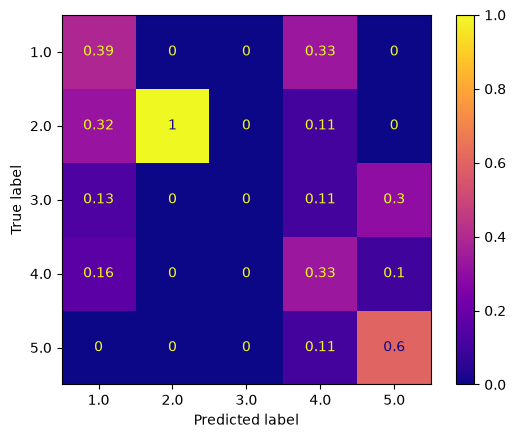

In [26]:
from sklearn.metrics import confusion_matrix
yhat = ovr.predict(x)
confmat = confusion_matrix(y,yhat)
print(confmat)
ConfusionMatrixDisplay.from_estimator(ovr,x,y,normalize='pred',cmap='plasma')
plt.savefig("CM_danger_sleep.png", dpi=300)
plt.show()

From the model scores and the confusion matrix, we can say the the model using total sleep is a bit better as the model using max lifespan. However both model aren't good at predicting danger index.

### Extra visualisation

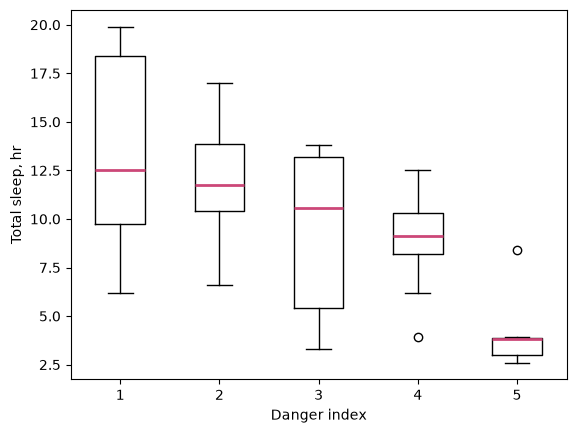

In [22]:
danger1 = df[df['danger_index']==1.0]['total_sleep']
danger2 = df[df['danger_index']==2.0]['total_sleep']
danger3 = df[df['danger_index']==3.0]['total_sleep']
danger4 = df[df['danger_index']==4.0]['total_sleep']
danger5 = df[df['danger_index']==5.0]['total_sleep']

plt.boxplot([danger1,danger2,danger3,danger4,danger5],medianprops=dict(color='#cc4778', linewidth=2))
plt.ylabel('Total sleep, hr')
plt.xlabel('Danger index')
plt.savefig("box_danger_sleep.png", dpi=300)
plt.show()

This graph also shows that the total sleep ours overlap quite a lot for the different danger indexes which makes it logical that the model doesn't perform very well.

## Comparing model using life span vs total sleep

We decided to test whether the two models are statistically different. To do so we constructed a null hypothesis and an alternative hypotesis.

H$_0$: There is no difference in the mean score of both models
H$_1$: There is a difference in the mean scorenof both models

We test this using a paired t-test, over the mean scores of different splits.

In [30]:
from scipy.stats import ttest_rel

y = df['danger_index'].to_numpy()
X1 = np.array(mlifespan).reshape(-1,1)
X2 = np.array(totalsleep).reshape(-1,1)

rskf = RepeatedStratifiedKFold(n_splits=2, n_repeats=10, random_state=42)
scores1 = cross_val_score(model1, X1, y, cv=rskf)
scores2 = cross_val_score(model2, X2, y, cv=rskf)

t_stat, p_value = ttest_rel(scores1, scores2)
print(f't_stat={t_stat},p={p_value}')

t_stat=-3.877605680944042,p=0.0010133344593128554


The p-value is below p<0.5, so we can say that the models are significantly different. The t_stat is negative which tells us that model 2's performance score is better.